In [ ]:
print("Name: Aryan Pilwalkar UIN: 231A016")
import pandas as pd
from datasets import load_dataset

# Load complete IMDB dataset
dataset = load_dataset("stanfordnlp/imdb")

#combine train and test
df = pd.concat(
    [dataset['train'].to_pandas(),
     dataset['test'].to_pandas()],
    ignore_index=True
)

Name: Aryan Pilwalkar UIN: 231A016


In [ ]:
print("Name: Aryan Pilwalkar UIN: 231A016")
#Rename target column
df = df.rename(columns={"label": "labels"})

print(df.shape)
print(df.columns)
print(df["labels"].value_counts())

Name: Aryan Pilwalkar UIN: 231A016
(50000, 2)
Index(['text', 'labels'], dtype='object')
labels
0    25000
1    25000
Name: count, dtype: int64


In [ ]:
print("Name: Aryan Pilwalkar UIN: 231A016")
df.head()

Name: Aryan Pilwalkar UIN: 231A016


,text,labels
0,I rented I AM CURIOUS-YELLOW from my video sto...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",0
2,If only to avoid making this type of film in t...,0
3,This film was probably inspired by Godard's Ma...,0
4,"Oh, brother...after hearing about this ridicul...",0


In [ ]:
print("Name: Aryan Pilwalkar UIN: 231A016")
df['labels'].count()

Name: Aryan Pilwalkar UIN: 231A016


np.int64(50000)

In [ ]:
print("Name: Aryan Pilwalkar UIN: 231A016")
print("\nMissing values:")
print(df.isnull().sum())

print("\nNumber of duplicates rows:")
print(df.duplicated().sum())

df["char_count"] = df["text"].astype(str).apply(len)

# df["text"].str.split() already returns a list of words
word_lists = df["text"].str.split()

df["word_count"] = word_lists.apply(len)

# Calculate unique word count by converting lists of words to sets
df["unique_word_count"] = word_lists.apply(lambda x: len(set(x)) if isinstance(x, list) else 0)

df["avg_word_length"] = word_lists.apply(
    lambda x: sum(len(word) for word in x) / max(len(x), 1) if isinstance(x, list) else 0
)

print("\nText Statistics:")
print(df[["char_count", "word_count", "unique_word_count", "avg_word_length"]].describe())

Name: Aryan Pilwalkar UIN: 231A016

Missing values:
text                 0
labels               0
char_count           0
word_count           0
avg_word_length      0
unique_word_count    0
dtype: int64

Number of duplicates rows:
418

Text Statistics:
         char_count    word_count  unique_word_count  avg_word_length
count  50000.000000  50000.000000        50000.00000     50000.000000
mean    1309.431020    231.156940          152.14090         4.640676
std      989.728014    171.343997           91.76515         0.340731
min       32.000000      4.000000            4.00000         1.239865
25%      699.000000    126.000000           94.00000         4.417904
50%      970.000000    173.000000          123.00000         4.627006
75%     1590.250000    280.000000          185.00000         4.847458
max    13704.000000   2470.000000         1118.00000        12.290909


In [ ]:
print("Name: Aryan Pilwalkar UIN: 231A016")
import re
import pandas as pd

def clean_text(text):
  text = text.lower()
  text = re.sub(r"<.*?>"," ", text)
  text = re.sub(r"[^a-z\s]"," ", text)
  text = re.sub(r"\s+"," ", text).strip()
  return text

df["clean_text"] = df["text"].astype(str).apply(clean_text)

print("\nOriginal Review:")
print(df["text"].iloc[0][:500])

print("\nCleaned Review:")
print(df["clean_text"].iloc[0][:500])

Name: Aryan Pilwalkar UIN: 231A016

Original Review:
I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attent

Cleaned Review:
i rented i am curious yellow from my video store because of all the controversy that surrounded it when it was first released in i also heard that at first it was seized by u s customs if it ever tried to enter this country therefore being a fan of films considered controversial i really had to see this for myself the plot is centered around a young swedish drama student named lena who wants to learn everything she can about 

Name: Aryan Pilwalkar UIN: 231A016


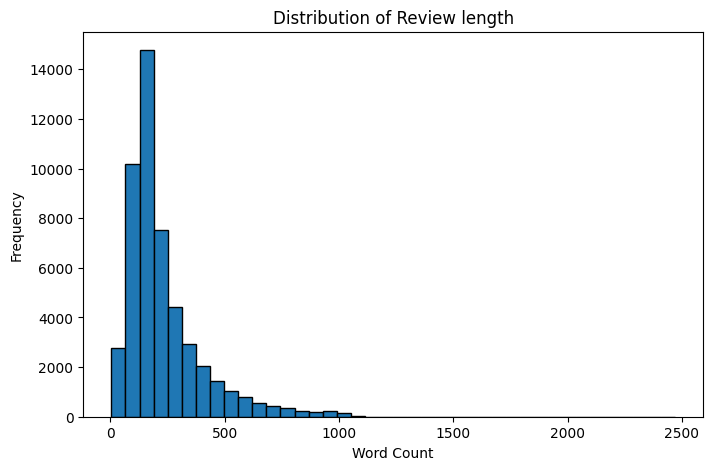

In [ ]:
print("Name: Aryan Pilwalkar UIN: 231A016")
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.hist(df["word_count"], bins=40 , edgecolor="black")
plt.xlabel("Word Count")
plt.ylabel("Frequency")
plt.title("Distribution of Review length")
plt.show()

In [ ]:
print("Name: Aryan Pilwalkar UIN: 231A016")
#create word list
all_words = " ".join(df["clean_text"]).split()

print("Total number of words:", len(all_words))
print("Vocabulary size:", len(set(all_words)))

Name: Aryan Pilwalkar UIN: 231A016
Total number of words: 11709196
Vocabulary size: 99420


Name: Aryan Pilwalkar UIN: 231A016


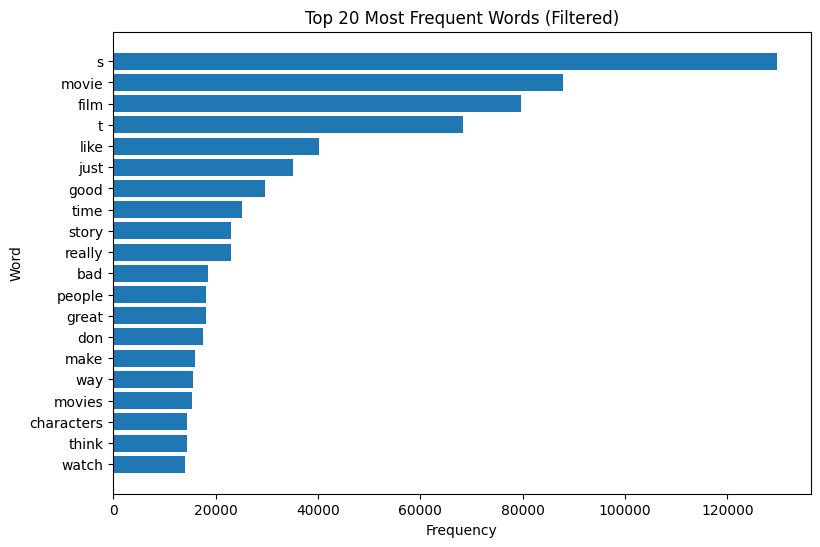

In [ ]:
print("Name: Aryan Pilwalkar UIN: 231A016")
from sklearn.feature_extraction.text import CountVectorizer
from collections import Counter
import matplotlib.pyplot as plt

vectorizer = CountVectorizer(
    stop_words="english"
)

vectorizer.fit(df["clean_text"])
stop_words = vectorizer.get_stop_words()
filtered_words = [word for word in all_words if word not in stop_words]
filtered_freq = Counter(filtered_words)
top_filtered_words = filtered_freq.most_common(20)
words = [word for word, count in top_filtered_words]
counts = [count for word, count in top_filtered_words]
plt.figure(figsize=(9,6))
plt.barh(words[::-1],counts[::-1])
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.title("Top 20 Most Frequent Words (Filtered)")
plt.show()

Name: Aryan Pilwalkar UIN: 231A016


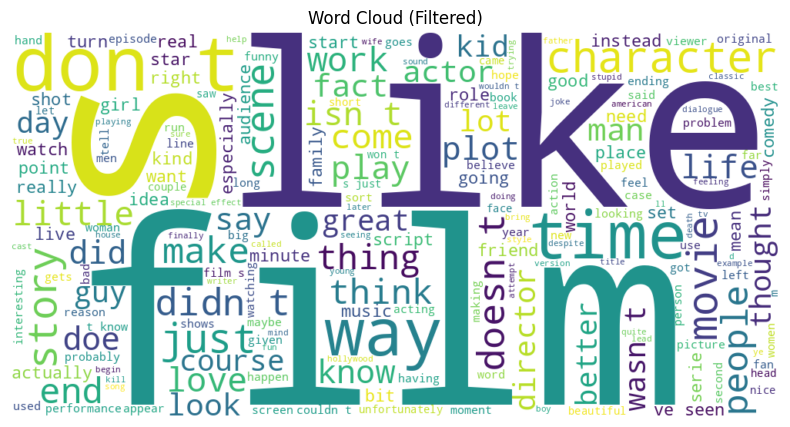

In [ ]:
print("Name: Aryan Pilwalkar UIN: 231A016")
from wordcloud import WordCloud

clean_text_combined = " ".join(filtered_words)

wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color="white",
    stopwords=stop_words
).generate(clean_text_combined)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud (Filtered)")
plt.show()

In [ ]:
print("Name: Aryan Pilwalkar UIN: 231A016")
bigram_vectorizer = CountVectorizer(ngram_range=(2, 2), stop_words='english')
bigram_matrix = bigram_vectorizer.fit_transform(df["clean_text"])

bigram_counts = bigram_matrix.sum(axis=0).A1
bigram_names = bigram_vectorizer.get_feature_names_out()

bigram_df = pd.DataFrame({'Bigram': bigram_names, 'frequency': bigram_counts})
bigram_df = bigram_df.sort_values(by='frequency', ascending=False)

print("\nTop 10 Bigrams:")
print(bigram_df.head(10))

Name: Aryan Pilwalkar UIN: 231A016

Top 10 Bigrams:
                  Bigram  frequency
2799056          ve seen       4168
2449781  special effects       2250
729336          don know       2202
1579147       low budget       1824
1559718       looks like       1679
2956729         year old       1601
1734893       movie just       1543
2854371       waste time       1526
1109129       good movie       1520
2281246           sci fi       1393


In [ ]:
print("Name: Aryan Pilwalkar UIN: 231A016")

Name: Aryan Pilwalkar UIN: 231A016


In [ ]:
print("Name: Aryan Pilwalkar UIN: 231A016")

Name: Aryan Pilwalkar UIN: 231A016


In [ ]:
print("Name: Aryan Pilwalkar UIN: 231A016")

Name: Aryan Pilwalkar UIN: 231A016


In [ ]:
print("Name: Aryan Pilwalkar UIN: 231A016")

Name: Aryan Pilwalkar UIN: 231A016


In [ ]:
print("Name: Aryan Pilwalkar UIN: 231A016")

Name: Aryan Pilwalkar UIN: 231A016


In [ ]:
print("Name: Aryan Pilwalkar UIN: 231A016")

Name: Aryan Pilwalkar UIN: 231A016


In [ ]:
print("Name: Aryan Pilwalkar UIN: 231A016")

Name: Aryan Pilwalkar UIN: 231A016


In [ ]:
print("Name: Aryan Pilwalkar UIN: 231A016")

Name: Aryan Pilwalkar UIN: 231A016
